In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf

#read the main dataset
df = pd.read_csv("../data/Sports_Injury_Prevention_Clinical_Biomechanics_Dataset.csv")

# Audit：Check if there are any missing values and what type each column is
print(df.info())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 48 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   athlete_id                   15000 non-null  str    
 1   session_id                   15000 non-null  str    
 2   sport_type                   15000 non-null  str    
 3   position_role                15000 non-null  str    
 4   gender                       15000 non-null  str    
 5   age                          15000 non-null  int64  
 6   height_cm                    15000 non-null  int64  
 7   weight_kg                    15000 non-null  int64  
 8   bmi                          15000 non-null  float64
 9   experience_years             15000 non-null  int64  
 10  training_duration_min        15000 non-null  int64  
 11  training_intensity           15000 non-null  str    
 12  previous_injury_history      15000 non-null  int64  
 13  recovery_days              

In [2]:
#Take the original injury_risk_level becomes the binary variable is_critical
df['is_critical'] = df['injury_risk_level'].apply(lambda x: 1 if x == 'Critical' else 0)

#  Calculate the injury rates and 95% confidence intervals of each sport
sport_stats = []
for sport in df['sport_type'].unique():
    subset = df[df['sport_type'] == sport]
    count = len(subset)
    critical_count = subset['is_critical'].sum()
    rate = critical_count / count
    
    # Calculate the 95% confidence interval (Wilson interval)
    ci_low, ci_high = proportion_confint(critical_count, count, alpha=0.05, method='wilson')
    
    sport_stats.append({
        'Sport': sport,
        'Total_Athletes': count,
        'Critical_Risk_Count': critical_count,
        'Risk_Rate': rate,
        'CI_Lower': ci_low,
        'CI_Upper': ci_high
    })

stats_df = pd.DataFrame(sport_stats).sort_values(by='Risk_Rate', ascending=False)
print("Calculate the 95% confidence interval (Wilson interval)")
display(stats_df)

Calculate the 95% confidence interval (Wilson interval)


,Sport,Total_Athletes,Critical_Risk_Count,Risk_Rate,CI_Lower,CI_Upper
9,Cricket,1490,1305,0.875839,0.858122,0.891623
2,Hockey,1450,1263,0.871034,0.852798,0.887310
5,Athletics,1494,1299,0.869478,0.851444,0.885617
7,Football,1475,1282,0.869153,0.850979,0.885408
1,Volleyball,1512,1314,0.869048,0.851104,0.885121
4,Rugby,1552,1345,0.866624,0.848801,0.882636
8,Basketball,1514,1308,0.863937,0.845743,0.880288
0,Tennis,1512,1305,0.863095,0.844846,0.879504
6,Swimming,1495,1288,0.861538,0.843102,0.878122
3,Badminton,1506,1293,0.858566,0.840053,0.875254


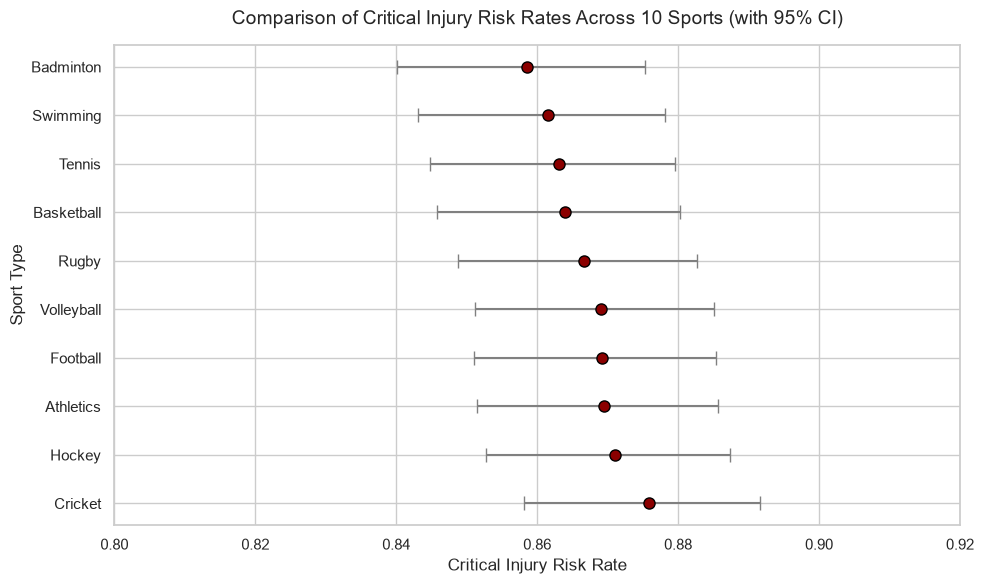

In [3]:
# Dot Plot with Error Bars
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Draw an error line
plt.errorbar(x=stats_df['Risk_Rate'], y=stats_df['Sport'], 
             xerr=[stats_df['Risk_Rate'] - stats_df['CI_Lower'], stats_df['CI_Upper'] - stats_df['Risk_Rate']], 
             fmt='o', color='darkred', ecolor='gray', capsize=5, markersize=8, markeredgecolor='black')

plt.title('Comparison of Critical Injury Risk Rates Across 10 Sports (with 95% CI)', fontsize=14, pad=15)
plt.xlabel('Critical Injury Risk Rate', fontsize=12)
plt.ylabel('Sport Type', fontsize=12)

plt.xlim(0.80, 0.92) 
plt.tight_layout()
plt.savefig('Figure1_DotPlot.png', dpi=300, bbox_inches='tight') 
plt.show()

In [4]:
#Chi-square Test
from scipy.stats import chi2_contingency

# Create a contingency list
contingency_table = pd.crosstab(df['sport_type'], df['is_critical'])

# Perform the chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Calculate the effect size(Cramér's V)
n = contingency_table.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))

print(f"Chi-square Statistic: {chi2:.3f}")
print(f"P-value: {p_value:.4f}")
print(f"Cramér's V (Effect Size): {cramers_v:.4f}")

if p_value < 0.05:
    print("=> Reject the null hypothesis: Significant differences exist across sports.")
else:
    print("=> Fail to reject the null hypothesis: No significant difference across sports (differences are likely due to random chance).")

Chi-square Statistic: 3.040
P-value: 0.9627
Cramér's V (Effect Size): 0.0142
=> Fail to reject the null hypothesis: No significant difference across sports (differences are likely due to random chance).


C:\Users\tar82\AppData\Local\Temp\ipykernel_29996\3449502729.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_critical', y='workload_ratio', data=df, palette="Blues")


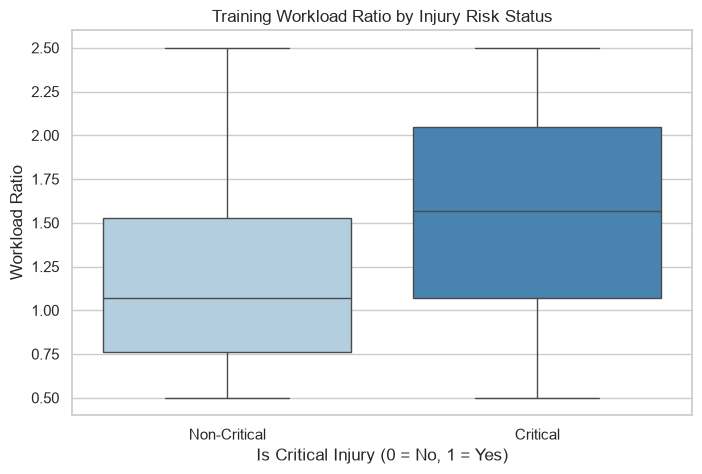

In [5]:
#Boxplot（Training load vs Risk status）
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_critical', y='workload_ratio', data=df, palette="Blues")
plt.title('Training Workload Ratio by Injury Risk Status')
plt.xlabel('Is Critical Injury (0 = No, 1 = Yes)')
plt.ylabel('Workload Ratio')
plt.xticks([0, 1], ['Non-Critical', 'Critical'])
plt.savefig('Figure2_Boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

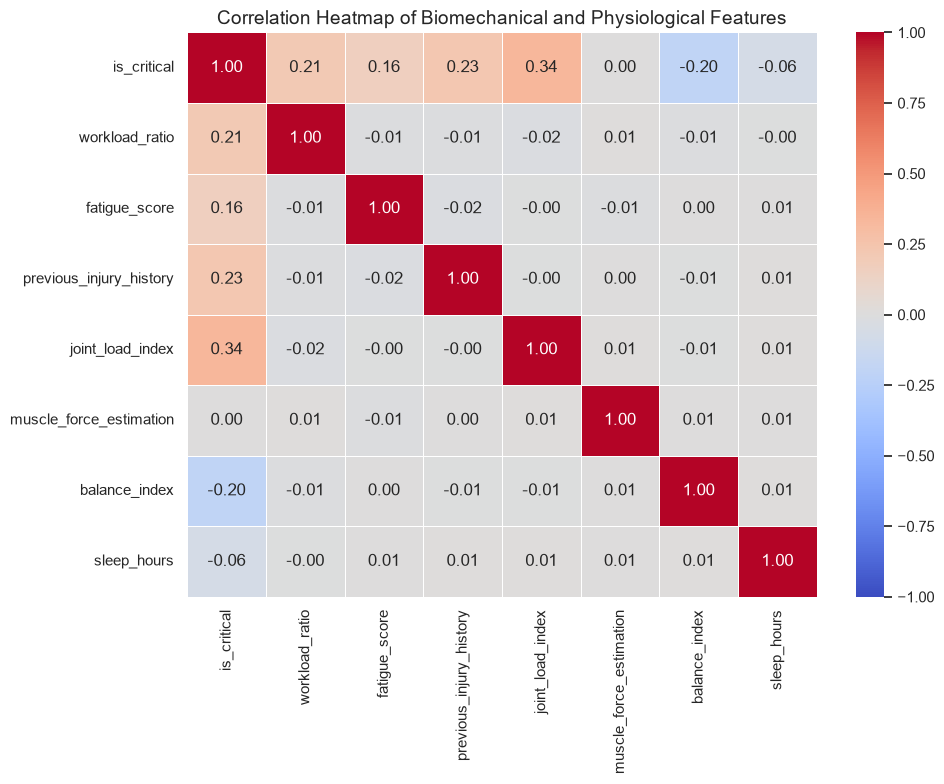

In [6]:
#Correlation Heatmap
features_to_corr = ['is_critical', 'workload_ratio', 'fatigue_score', 
                    'previous_injury_history', 'joint_load_index', 
                    'muscle_force_estimation', 'balance_index', 'sleep_hours']

# Calculate the correlation coefficient matrix
corr_matrix = df[features_to_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Biomechanical and Physiological Features', fontsize=14)
plt.tight_layout()
plt.savefig('Figure3_Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

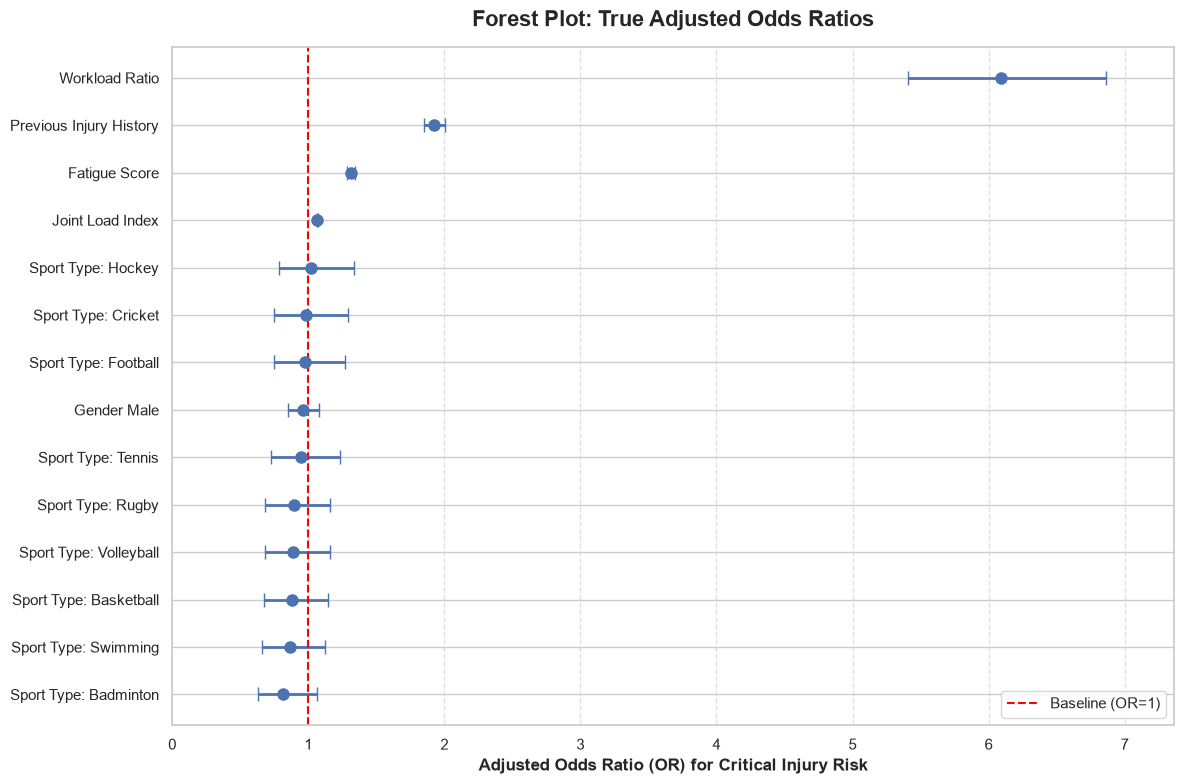

In [7]:
#Forest Plot

features = ['sport_type', 'gender', 'workload_ratio', 'fatigue_score', 'previous_injury_history', 'joint_load_index']
target = 'is_critical'

df_model = df[features + [target]].dropna()

X = pd.get_dummies(df_model[features], drop_first=True, dtype=int)
y = df_model[target]
X = sm.add_constant(X)

model = sm.Logit(y, X)
result = model.fit(disp=0) 

params = result.params
conf = result.conf_int()
conf.columns = ['2.5%_coef', '97.5%_coef']

conf['Odds Ratio'] = np.exp(params)
conf['2.5%_OR'] = np.exp(conf['2.5%_coef'])
conf['97.5%_OR'] = np.exp(conf['97.5%_coef'])
conf['p-value'] = result.pvalues

conf = conf.drop('const', errors='ignore')
conf = conf.sort_values(by='Odds Ratio', ascending=True)

display_labels = [name.replace('_', ' ').replace('type ', 'Type: ').title() for name in conf.index]
display_labels = [label.replace('Ratio', 'Ratio').replace('History', 'History') for label in display_labels]

fig, ax = plt.subplots(figsize=(12, 8))
y_pos = np.arange(len(conf))

xerr = [conf['Odds Ratio'] - conf['2.5%_OR'], conf['97.5%_OR'] - conf['Odds Ratio']]
ax.errorbar(conf['Odds Ratio'], y_pos, xerr=xerr, 
            fmt='o', capsize=5, markersize=8, elinewidth=2)

ax.axvline(x=1, color='red', linestyle='--', linewidth=1.5, label='Baseline (OR=1)')

ax.set_yticks(y_pos)
ax.set_yticklabels(display_labels, fontsize=11)
ax.set_xlabel('Adjusted Odds Ratio (OR) for Critical Injury Risk', fontsize=12, fontweight='bold')
ax.set_title('Forest Plot: True Adjusted Odds Ratios', fontsize=16, fontweight='bold', pad=15)

ax.set_xlim(0, max(conf['97.5%_OR']) + 0.5)

ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()

plt.savefig('Figure4_Forest_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
#dataset2
#1. read and analysis the dataset
df2 = pd.read_csv("../data/multimodal_sports_injury_dataset.csv")
print("shape:", df2.shape)
display(df2.head(3))

# Missing rate
miss = (df2.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0].round(2)
print("Missing columns (missing rate %):")
display(miss.to_frame("missing_%").T)

# The original distribution of the target variable (three categories: 0/1/2)
print("\ninjury_occurred original distribution:")
print(df2["injury_occurred"].value_counts(dropna=False))
print("\nrate:")
print(df2["injury_occurred"].value_counts(normalize=True).round(4))

shape: (15420, 29)


,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,...,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,sport_type,gender,age,bmi
0,1,NaN,37.048668,76.481477,5.466370,77.899691,0.375825,10.000000,126.480118,2.654327,...,5.678475,79.106564,548.417962,45.028687,0,1,Basketball,Female,18,25.105748
1,1,40.000000,36.929536,72.363938,6.899090,74.845323,0.279165,310.293156,157.631630,3.431107,...,NaN,116.954654,538.043815,42.254717,2,2,Basketball,Female,18,25.105748
2,1,76.174609,36.334841,100.000000,9.574152,83.538316,0.334061,158.659094,81.766287,0.800000,...,6.643242,96.354742,647.784339,61.870056,0,3,Basketball,Female,18,25.105748


Missing columns (missing rate %):


,training_intensity,muscle_activity,sleep_quality,gait_speed,hydration_level,heart_rate
missing_%,4.1,3.7,3.2,2.8,2.5,2.3



injury_occurred original distribution:
injury_occurred
0    9868
1    3238
2    2314
Name: count, dtype: int64

rate:
injury_occurred
0    0.6399
1    0.2100
2    0.1501
Name: proportion, dtype: float64


In [11]:
#2. Objective binarization (0= no damage, 1/2= damage)
df2["injury_bin"] = (df2["injury_occurred"] > 0).astype(int)
print("injury after binarization_bin distribution (proportion):")
print(df2["injury_bin"].value_counts(normalize=True).round(4))

injury after binarization_bin distribution (proportion):
injury_bin
0    0.6399
1    0.3601
Name: proportion, dtype: float64


corr(training_load, intensity×duration) = 0.825


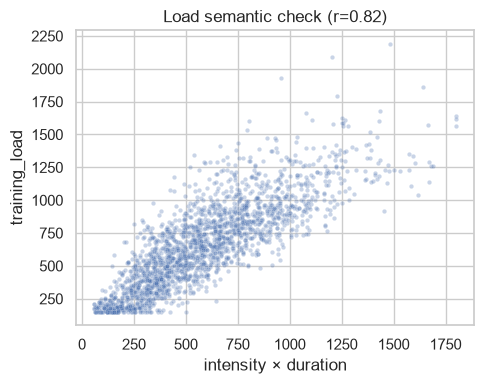

In [12]:
#3. Load semantic inspection
df2["load_calc"] = df2["training_intensity"] * df2["training_duration"]
corr = df2[["training_load", "load_calc"]].dropna().corr().iloc[0, 1]
print(f"corr(training_load, intensity×duration) = {corr:.3f}")

samp = df2[["training_load", "load_calc"]].dropna().sample(min(2000, len(df2)), random_state=42)
plt.figure(figsize=(5, 4))
sns.scatterplot(data=samp, x="load_calc", y="training_load", alpha=0.3, s=10)
plt.xlabel("intensity × duration")
plt.ylabel("training_load")
plt.title(f"Load semantic check (r={corr:.2f})")
plt.tight_layout()
plt.savefig('Figure5_dataset2_Scatter_plot.png', dpi=300, bbox_inches='tight')
plt.show()

C:\Users\tar82\AppData\Local\Temp\ipykernel_29996\109972231.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df2, x="injury_status", y="training_load", palette=["#A1C3D1", "#C94C4C"], showfliers=False)


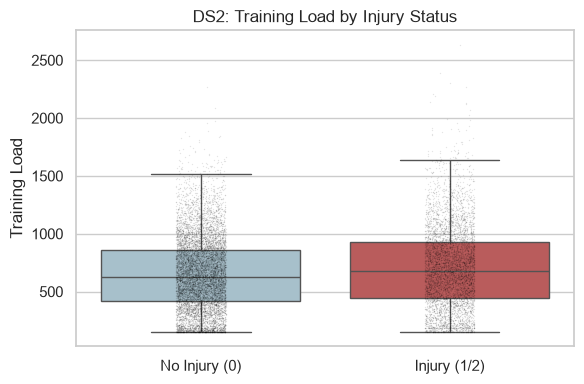

In [13]:
#4. Box plot
df2["injury_status"] = df2["injury_occurred"].apply(lambda x: "No Injury (0)" if x == 0 else "Injury (1/2)")

plt.figure(figsize=(6, 4))

sns.boxplot(data=df2, x="injury_status", y="training_load", palette=["#A1C3D1", "#C94C4C"], showfliers=False)
sns.stripplot(data=df2, x="injury_status", y="training_load", color="black", alpha=0.1, size=1, jitter=True)

plt.title("DS2: Training Load by Injury Status")
plt.xlabel("")
plt.ylabel("Training Load")
plt.tight_layout()
plt.savefig('Figure6_dataset2_Box_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
#dataset3
df3 = pd.read_csv("../data/university-football-injury-prediction-dataset.csv")
print("DS3 shape:", df3.shape)
print("\n All column names:")
for col in df3.columns:
    print(f"{col}: {df3[col].dtype}")
print("Target variable Injury_Next_Season distribution：")
print(df3["Injury_Next_Season"].value_counts(normalize=True).round(3))

DS3 shape: (800, 19)

 All column names:
Age: int64
Height_cm: int64
Weight_kg: int64
Position: str
Training_Hours_Per_Week: float64
Matches_Played_Past_Season: int64
Previous_Injury_Count: int64
Knee_Strength_Score: float64
Hamstring_Flexibility: float64
Reaction_Time_ms: float64
Balance_Test_Score: float64
Sprint_Speed_10m_s: float64
Agility_Score: float64
Sleep_Hours_Per_Night: float64
Stress_Level_Score: float64
Nutrition_Quality_Score: float64
Warmup_Routine_Adherence: int64
Injury_Next_Season: int64
BMI: float64
Target variable Injury_Next_Season distribution：
Injury_Next_Season
0    0.5
1    0.5
Name: proportion, dtype: float64


Previous Injury OR: 2.04 (95% CI: 1.77 - 2.34), p=7.57e-24


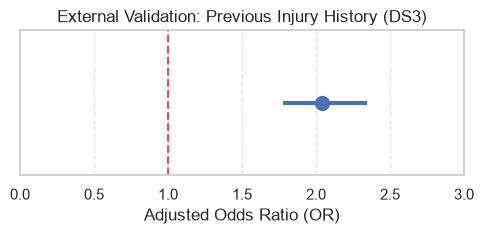

In [15]:
model = smf.logit("Injury_Next_Season ~ Previous_Injury_Count", data=df3).fit(disp=0)
or_val = np.exp(model.params["Previous_Injury_Count"])
ci = np.exp(model.conf_int().loc["Previous_Injury_Count"]).values
p_val = model.pvalues["Previous_Injury_Count"]

print(f"Previous Injury OR: {or_val:.2f} (95% CI: {ci[0]:.2f} - {ci[1]:.2f}), p={p_val:.2e}")

plt.figure(figsize=(5, 2.5))
plt.axvline(1, color='red', linestyle='--', alpha=0.7)
plt.plot(or_val, 0, 'o', color='#4C72B0', markersize=10)
plt.hlines(0, ci[0], ci[1], color='#4C72B0', linewidth=3)

plt.yticks([]) 
plt.xlabel("Adjusted Odds Ratio (OR)")
plt.title("External Validation: Previous Injury History (DS3)")
plt.xlim(0, max(ci[1] + 0.5, 3)) 
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Figure7_dataset3_Forest_plot.png', dpi=300, bbox_inches='tight')
plt.show()